# Faster R-CNN (ResNet-50 FPN v2) — Training

Fine-tunes torchvision's COCO-pretrained model on Construction Site Safety. The test-set evaluation is in
[`faster_rcnn_eval.ipynb`](faster_rcnn_eval.ipynb).

| Setting | Value |
|---|---|
| Input size | 640×640 from the pipeline, resized to 800×800 inside the model (torchvision's default) |
| Optimizer | SGD, lr 0.02 × batch / 16, momentum 0.9, weight decay 1e-4 (torchvision reference) |
| LR schedule | linear warmup over the first 1000 iterations, then cosine decay over `EPOCHS` (torchvision reference) |
| Batch size | 4 |
| Epochs | 100 |
| Early stopping | patience 20 on validation mAP@50-95 |
| Checkpoint | best validation mAP@50-95 → `models/faster_rcnn/weights/best.pt` |

**Data augmentation** (`ppe_detection_evaluation.dataset.augmentations`) is horizontal flip (p = 0.5) only, applied
with Albumentations. The Ultralytics models use Ultralytics' defaults with mosaic off instead. Every image is already 640×640, so
the resize to 640×640 is a no-op. Validation and test images are not augmented.


In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parents[1] / "src"))

import json

%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import torch
from torch.utils.data import DataLoader
from torchvision.models.detection import FasterRCNN_ResNet50_FPN_V2_Weights, fasterrcnn_resnet50_fpn_v2
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor

from ppe_detection_evaluation import FASTER_RCNN, EvaluationFramework
from ppe_detection_evaluation.classes import DEFAULT_CLASS_NAMES
from ppe_detection_evaluation.dataset.augmentations import build_train_transform
from ppe_detection_evaluation.dataset.core import (
    check_dataset,
    class_box_counts,
    download_dataset,
    list_images,
    load_eval_example,
    xyxy_to_cxcywh,
)
from ppe_detection_evaluation.dataset.torchvision_adapter import TorchvisionDataset, collate, seed_worker
from ppe_detection_evaluation.experiment import DATA_ROOT, IMAGE_SIZE, MAX_EPOCHS, MODELS_DIR, PRETRAINED_DIR, SEED
from ppe_detection_evaluation.utilities.visualize import plot_examples

## Hyperparameters

Everything tunable for this model is set in the next cell. `SEED`, `IMAGE_SIZE` and `MAX_EPOCHS` are shared by all four
notebooks (`experiment.py`): the seed makes runs reproducible. Epochs, early stopping, batch size and optimizer settings
are chosen per model.

In [2]:
EPOCHS = 100
PATIENCE = 20  # epochs without a validation mAP@50-95 improvement
BATCH_SIZE = 8                  
LR = 0.02 * BATCH_SIZE / 16     # torchvision reference: lr 0.02 at batch 16, scaled linearly
MOMENTUM = 0.9
WEIGHT_DECAY = 1e-4

In [3]:
# SEED, DATA_ROOT and the model folders come from experiment.py and are shared by all four notebooks.
RUN_DIR = MODELS_DIR / "faster_rcnn"          # training curves and history
WEIGHTS_DIR = RUN_DIR / "weights"       # best.pt / last.pt
WEIGHTS_DIR.mkdir(parents=True, exist_ok=True)
torch.hub.set_dir(PRETRAINED_DIR / "torchvision")  # COCO weights download here instead of ~/.cache

NUM_CLASSES = len(DEFAULT_CLASS_NAMES) + 1  # + background at index 0

torch.manual_seed(SEED)  # makes the new head's random initialisation reproducible
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
print(f"Device: {DEVICE} | Classes: {NUM_CLASSES} (incl. background) | Epochs: {EPOCHS} | Batch: {BATCH_SIZE}")

Device: cuda | Classes: 11 (incl. background) | Epochs: 100 | Batch: 8


## 1. Dataset

[Construction Site Safety](https://www.kaggle.com/datasets/snehilsanyal/construction-site-safety-image-dataset-roboflow)
(Roboflow, via Kaggle), with all 10 classes. `download_dataset` is a no-op once `data/construction-site-safety` exists,
so all four notebooks share one copy.

In [4]:
download_dataset(DATA_ROOT)
splits = check_dataset(DATA_ROOT)  # raises if the class order differs from DEFAULT_CLASS_NAMES

counts = {split: class_box_counts(DATA_ROOT, split) for split in splits}
print(f"{'Boxes':<10}" + "".join(f"{split.capitalize():>8}" for split in splits))
for name in counts["train"]:
    print(f"{name:<10}" + "".join(f"{counts[split][name]:>8}" for split in splits))
print("-" * (10 + 8 * len(splits)))
print(f"{'Images':<10}" + "".join(f"{n:>8}" for n in splits.values()))

Boxes        Train   Valid    Test
Hardhat       3145      79     110
Mask          1651      21      28
NO-Hardhat    2317      69      41
NO-Mask       3097      74      79
NO-Safety Vest    3962     106      90
Person        9532     166     174
Safety Cone    3366      44      92
Safety Vest    3033      41      61
machinery     5247      55      44
vehicle       1545      42      41
----------------------------------
Images        2605     114      82


## 2. Training data

`TorchvisionDataset` applies the shared augmentation to each image and returns it in
torchvision's format: a float image in [0, 1] and a target with pixel xyxy `boxes` and `labels` shifted by +1 (0 is
background). Normalisation and resizing to the network input are left to the model's own transform.

In [5]:
train_ds = TorchvisionDataset(DATA_ROOT, "train", build_train_transform(seed=SEED))
train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=8,
    pin_memory=True,
    persistent_workers=True,
    collate_fn=collate,
    worker_init_fn=seed_worker,
    generator=torch.Generator().manual_seed(SEED),
)
print(f"Train: {len(train_ds)} images | {len(train_loader)} batches per epoch")

Train: 2605 images | 326 batches per epoch


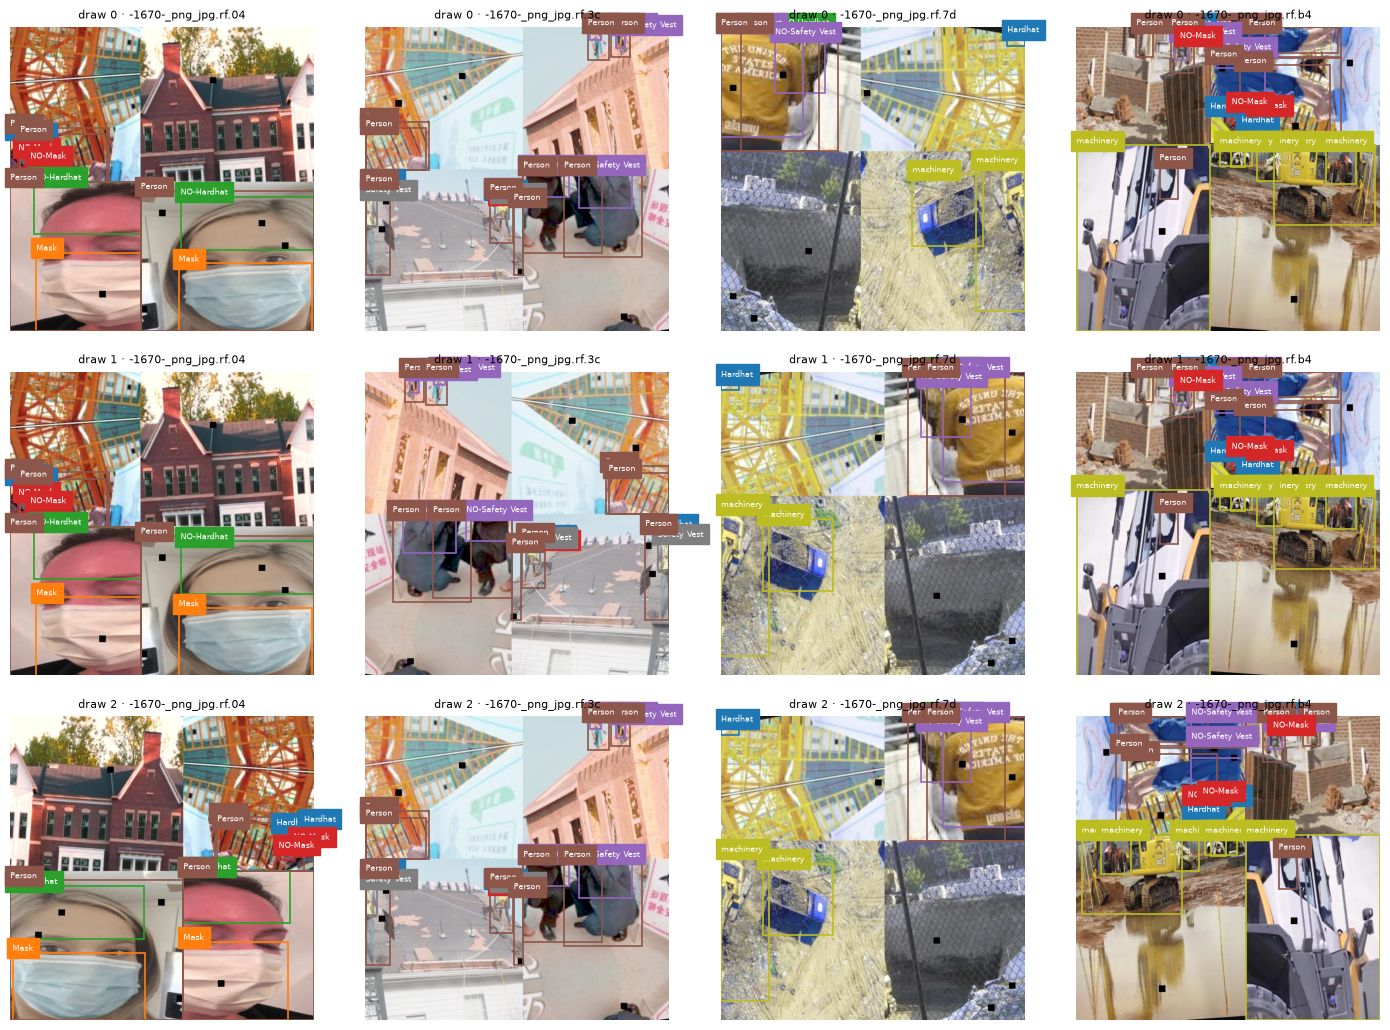

In [6]:
# Four training images (columns), each drawn three times (rows) to show the augmentation's range
examples, titles = [], []
for draw in range(3):
    for i in range(4):
        image, target = train_ds[i]
        image = (image * 255).round().byte().permute(1, 2, 0).numpy()
        examples.append((image, target["boxes"].numpy(), target["labels"].numpy() - 1))
        titles.append(f"draw {draw} · {train_ds.image_paths[i].name[:20]}")
plot_examples(examples, titles);

## 3. Model

COCO-pretrained Faster R-CNN with its final box predictor replaced. The class-score layer goes from 91 COCO classes to
11 (10 + background), and so does the box-offset layer, because Faster R-CNN predicts a separate box per class. The
backbone, FPN and region proposal network keep their COCO weights. The model's own transform resizes the 640×640
pipeline images to its native 800×800 (torchvision's default `min_size=800`), as SSD uses its native 300×300;
predicted boxes come back in 640×640 coordinates.

In [7]:
model = fasterrcnn_resnet50_fpn_v2(
    weights=FasterRCNN_ResNet50_FPN_V2_Weights.COCO_V1,
    box_score_thresh=0.001,  # same detection threshold as the other models (torchvision default 0.05)
)

# The pretrained predictor outputs 91 COCO classes; replace it with one for our 10 classes + background.
in_features = model.roi_heads.box_predictor.cls_score.in_features
model.roi_heads.box_predictor = FastRCNNPredictor(in_features, NUM_CLASSES)
model = model.to(DEVICE)

total = sum(p.numel() for p in model.parameters())
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total params:     {total:,}")
print(f"Trainable params: {trainable:,}")

7.1%

Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_v2_coco-dd69338a.pth" to /workspace/42177-image-processing-ppe-detection/models/pretrained/torchvision/checkpoints/fasterrcnn_resnet50_fpn_v2_coco-dd69338a.pth


100.0%


Total params:     43,302,278
Trainable params: 43,076,934


## 4. Training

`train_one_epoch` runs one pass over the augmented training set; `validation_loss` computes the same loss on a split
without augmentation; `evaluate` scores a split with the evaluation framework. After each epoch the validation split is scored and the checkpoint with the best
validation mAP@50-95 is kept.

In [8]:
def train_one_epoch(model, loader, optimizer, epoch):
    model.train()
    running_loss, total_images = 0.0, 0

    # torchvision reference: linear warmup over the first epoch's first 1000 iterations
    warmup = None
    if epoch == 0:
        warmup = torch.optim.lr_scheduler.LinearLR(optimizer, start_factor=1e-3, total_iters=min(1000, len(loader) - 1))

    for step, (images, targets) in enumerate(loader):
        images = [img.to(DEVICE) for img in images]
        targets = [{k: v.to(DEVICE) for k, v in t.items()} for t in targets]
        loss = sum(model(images, targets).values())
        if not torch.isfinite(loss):
            raise FloatingPointError(f"Loss is {loss.item()} at epoch {epoch}, step {step}")

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        if warmup is not None:
            warmup.step()

        running_loss += loss.item() * len(images)
        total_images += len(images)

    return running_loss / total_images  # mean loss per image over the epoch

In [9]:
@torch.inference_mode()
def evaluate(model, split):
    """Score a split with the evaluation framework; images are only resized to 640×640, no augmentation."""
    model.eval()
    fw = EvaluationFramework(FASTER_RCNN)
    for path in list_images(DATA_ROOT, split):
        image, gt_boxes, gt_labels = load_eval_example(path)
        out = model([torch.from_numpy(image).permute(2, 0, 1).float().div(255).to(DEVICE)])[0]
        fw.add(
            path.stem,
            out["boxes"].cpu().numpy(),
            out["scores"].cpu().numpy(),
            out["labels"].cpu().numpy(),
            xyxy_to_cxcywh(gt_boxes, IMAGE_SIZE, IMAGE_SIZE),
            gt_labels,
        )
    return fw.evaluate()

In [10]:
@torch.inference_mode()
def validation_loss(model, split):
    """Mean loss per image on a split, the same quantity `train_one_epoch` reports.

    Detection models only return losses in train mode. BatchNorm layers stay in eval mode, so that scoring the
    validation split does not update their running statistics.
    """
    model.train()
    for module in model.modules():
        if isinstance(module, torch.nn.BatchNorm2d):
            module.eval()
    paths = list_images(DATA_ROOT, split)
    total_loss = 0.0
    for start in range(0, len(paths), BATCH_SIZE):
        images, targets = [], []
        for path in paths[start : start + BATCH_SIZE]:
            image, boxes, labels = load_eval_example(path)
            images.append(torch.from_numpy(image).permute(2, 0, 1).float().div(255).to(DEVICE))
            targets.append({
                "boxes": torch.from_numpy(boxes).reshape(-1, 4).to(DEVICE),
                "labels": torch.from_numpy(labels + 1).to(DEVICE),  # +1: index 0 is background
            })
        total_loss += sum(model(images, targets).values()).item() * len(images)
    return total_loss / len(paths)

In [11]:
params = [p for p in model.parameters() if p.requires_grad]
optimizer = torch.optim.SGD(params, lr=LR, momentum=MOMENTUM, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

best_map = -1.0
epochs_since_best = 0
history = {"train_loss": [], "val_loss": [], "val_map50": [], "val_map": []}

for epoch in range(EPOCHS):
    train_loss = train_one_epoch(model, train_loader, optimizer, epoch)
    scheduler.step()
    val_loss = validation_loss(model, "valid")
    val = evaluate(model, "valid")["detection"]["groups"]["all"]

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_map50"].append(val["mAP50"])
    history["val_map"].append(val["mAP"])
    print(f"Epoch {epoch + 1:3d}/{EPOCHS}  loss={train_loss:.4f}/{val_loss:.4f}  val mAP@50={val['mAP50']:.4f}  mAP@50-95={val['mAP']:.4f}")

    if val["mAP"] > best_map:
        best_map = val["mAP"]
        epochs_since_best = 0
        torch.save(model.state_dict(), WEIGHTS_DIR / "best.pt")
        print(f"  → Best saved (mAP@50-95={best_map:.4f})")
    else:
        epochs_since_best += 1
        if epochs_since_best >= PATIENCE:
            print(f"Early stopping: no mAP@50-95 improvement for {PATIENCE} epochs")
            break

torch.save(model.state_dict(), WEIGHTS_DIR / "last.pt")
(RUN_DIR / "history.json").write_text(json.dumps(history, indent=2))

Epoch   1/100  loss=1.4561/0.5128  val mAP@50=0.6845  mAP@50-95=0.3305
  → Best saved (mAP@50-95=0.3305)
Epoch   2/100  loss=0.8678/0.4655  val mAP@50=0.7418  mAP@50-95=0.3575
  → Best saved (mAP@50-95=0.3575)
Epoch   3/100  loss=0.7231/0.4493  val mAP@50=0.7907  mAP@50-95=0.3843
  → Best saved (mAP@50-95=0.3843)
Epoch   4/100  loss=0.6468/0.4286  val mAP@50=0.7975  mAP@50-95=0.4087
  → Best saved (mAP@50-95=0.4087)
Epoch   5/100  loss=0.5856/0.4171  val mAP@50=0.8148  mAP@50-95=0.4420
  → Best saved (mAP@50-95=0.4420)
Epoch   6/100  loss=0.5390/0.3988  val mAP@50=0.8409  mAP@50-95=0.4495
  → Best saved (mAP@50-95=0.4495)
Epoch   8/100  loss=0.4637/0.3964  val mAP@50=0.8346  mAP@50-95=0.4330
Epoch   9/100  loss=0.4383/0.4146  val mAP@50=0.8456  mAP@50-95=0.4534
  → Best saved (mAP@50-95=0.4534)
Epoch  10/100  loss=0.4115/0.4040  val mAP@50=0.8460  mAP@50-95=0.4672
  → Best saved (mAP@50-95=0.4672)
Epoch  11/100  loss=0.3863/0.3850  val mAP@50=0.8544  mAP@50-95=0.4770
  → Best saved (mA

5797

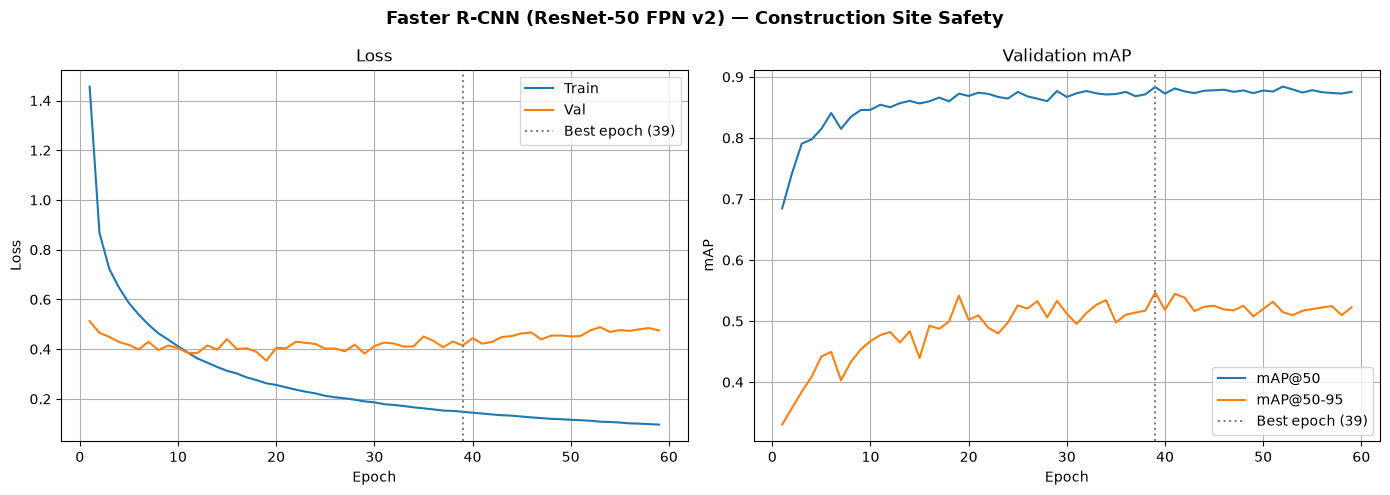

In [12]:
epochs_x = range(1, len(history["train_loss"]) + 1)
best_epoch = int(np.argmax(history["val_map"])) + 1

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
ax1.plot(epochs_x, history["train_loss"], label="Train")
ax1.plot(epochs_x, history["val_loss"], label="Val")
ax1.set(xlabel="Epoch", ylabel="Loss", title="Loss")
ax2.plot(epochs_x, history["val_map50"], label="mAP@50")
ax2.plot(epochs_x, history["val_map"], label="mAP@50-95")
ax2.set(xlabel="Epoch", ylabel="mAP", title="Validation mAP")
for ax in (ax1, ax2):
    ax.axvline(best_epoch, color="grey", linestyle=":", lw=1.5, label=f"Best epoch ({best_epoch})")
    ax.legend()
    ax.grid(True)

plt.suptitle("Faster R-CNN (ResNet-50 FPN v2) — Construction Site Safety", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(RUN_DIR / "training_curves.png", dpi=150)
plt.show()

Next: evaluate `models/faster_rcnn/weights/best.pt` on the test split with [`faster_rcnn_eval.ipynb`](faster_rcnn_eval.ipynb).